# 05 · Feature importance & interpretability

TreeSHAP on the named-feature Model C (`C_combo`: market + news volume + anchor axes + novelty + entity channels + BERTopic shares + sentiment), refitted on train+val and explained on the test days.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebook' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
FIG = 'report/figures/'
from src.analysis import interpret as it

/Users/harfi/Documents/Project/ugm/nlp3/.venv/lib/python3.12/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


news volume             0.0262
novelty / dispersion    0.0781
sentiment               0.1574
market                  0.4902
anchor axes             0.9386
entity channels         0.9748
topics                  1.4169
dtype: float64

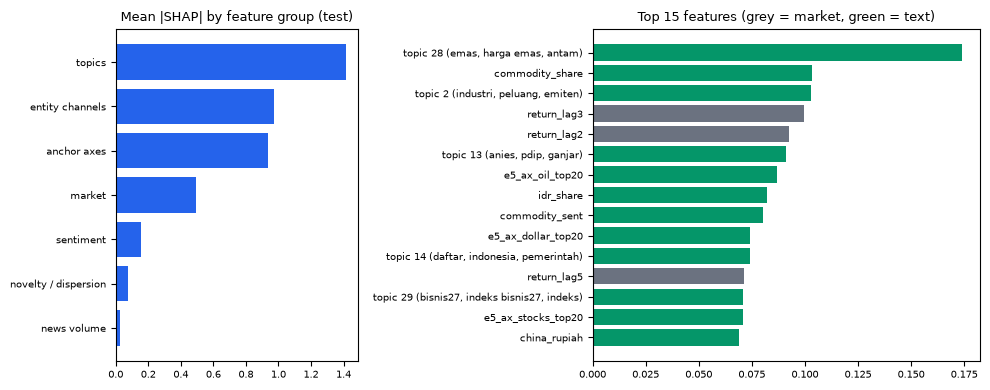

In [2]:
groups, imp, shap_df, fig = it.shap_summary(FIG + 'shap_groups.pdf')
groups.round(4)

In [3]:
names = it.topic_names()
imp.sort_values(ascending=False).head(20).rename(index=lambda c: names.get(c, c)).round(4)

topic 28 (emas, harga emas, antam)              0.1738
commodity_share                                 0.1034
topic 2 (industri, peluang, emiten)             0.1027
return_lag3                                     0.0997
return_lag2                                     0.0923
topic 13 (anies, pdip, ganjar)                  0.0909
e5_ax_oil_top20                                 0.0871
idr_share                                       0.0821
commodity_sent                                  0.0802
e5_ax_dollar_top20                              0.0744
topic 14 (daftar, indonesia, pemerintah)        0.0739
return_lag5                                     0.0713
topic 29 (bisnis27, indeks bisnis27, indeks)    0.0710
e5_ax_stocks_top20                              0.0707
china_rupiah                                    0.0688
topic 1 (triliun, miliar, dividen)              0.0624
sent_neg_share                                  0.0621
geo_sent                                        0.0619
usd_share 

## Largest prediction shifts vs Model A, and the news behind them

In [4]:
shifts = it.largest_shifts(shap_df, 8)
shifts

W1118 22:14:31.005000 97204 .venv/lib/python3.12/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

,date,return_%,actual,P_A,P_C,top_text_feature,shap,headlines
0,2025-12-11,-0.120,DOWN,0.150,0.750,usd_sent,0.241,"[Usai Kerek Bea Impor Produk China, Meksiko Lobi AS Minta Relaksasi Tarif Baja, Mendag Bantah Kesepakatan Tarif AS-I..."
1,2026-02-12,0.268,UP,0.722,0.238,e5_ax_oil_top20,-0.280,"[[+0.038] Indeks Bisnis-27 Menguat 1,26%, BRPT Hingga MAPI Pimpin Kenaikan, [+0.036] Modal Kuat Indosat (ISAT) Lanju..."
2,2026-05-21,-0.068,DOWN,0.345,0.764,commodity_share,0.395,"[Prabowo Blak-blakan soal Aturan Jual Sawit-Batu Bara Cs Wajib Lewat BUMN, Prabowo Ogah Harga Sawit, Nikel & Emas Di..."
3,2026-01-22,-0.360,DOWN,0.229,0.636,commodity_share,0.404,"[Harga Emas Antam Hari Ini (21/1) Melonjak Rp67.000 Sentuh Rp2,77 Juta per Gram, Harga Emas Perhiasan Hari Ini 21 Ja..."
4,2026-08-03,-0.372,DOWN,0.648,0.253,usd_share,0.197,"[Rupiah Dibuka Menguat Sentuh Rp18.055 per Dolar AS, Terangkat Data Ekonomi AS, NAB Reksa Dana Rontok, Bersaing deng..."
5,2026-05-12,0.567,UP,0.428,0.815,commodity_share,0.348,"[Tabel Harga Buyback Emas Antam Hari Ini Senin, 11 Mei 2026 & Besaran Pajaknya, Trump dan Netanyahu Tekan Iran, Harg..."
6,2026-04-14,0.076,UP,0.384,0.754,commodity_share,0.382,"[Jalan Buntu Dialog AS-Iran Bikin Minyak Dunia Melejit, Saham MEDC, ENRG Cs Tancap Gas, Harga Buyback Emas Antam Nai..."
7,2026-01-05,0.137,UP,0.423,0.791,commodity_sent,0.411,"[Emiten CPO Austindo Nusantara (ANJT) Tutup Usaha Edamame dan Sagu, Pertamina Hulu Energi Temukan Sumber Minyak Baru..."


In [5]:
for r in shifts.itertuples():
    print(r.date, r.actual, f'P_A={r.P_A} P_C={r.P_C}', r.top_text_feature)
    for h in r.headlines: print('   ', h)

2025-12-11 DOWN P_A=0.15 P_C=0.75 usd_sent
    Usai Kerek Bea Impor Produk China, Meksiko Lobi AS Minta Relaksasi Tarif Baja
    Mendag Bantah Kesepakatan Tarif AS-Indonesia Terancam Batal
    Anak Buah Airlangga Tepis Kabar Kesepakatan Tarif Trump Terancam Batal
2026-02-12 UP P_A=0.722 P_C=0.238 e5_ax_oil_top20
    [+0.038] Indeks Bisnis-27 Menguat 1,26%, BRPT Hingga MAPI Pimpin Kenaikan
    [+0.036] Modal Kuat Indosat (ISAT) Lanjutkan Pertumbuhan Kinerja
    [+0.031] Sambut Ramadan, GOTO Perkuat Mesin Transaksi Lewat Ekspansi GoPay
2026-05-21 DOWN P_A=0.345 P_C=0.764 commodity_share
    Prabowo Blak-blakan soal Aturan Jual Sawit-Batu Bara Cs Wajib Lewat BUMN
    Prabowo Ogah Harga Sawit, Nikel & Emas Diatur Negara Lain: Kita Tentukan Sendiri!
    Ekspor Batu Bara-Sawit Satu Pintu via BUMN Berlaku 1 Juni, Implementasi Bertahap
2026-01-22 DOWN P_A=0.229 P_C=0.636 commodity_share
    Harga Emas Antam Hari Ini (21/1) Melonjak Rp67.000 Sentuh Rp2,77 Juta per Gram
    Harga Emas Perhiasan 

## What the attention model looked at (test days with the largest moves)

In [6]:
att = pd.read_csv('results/predictions/attention_top_headlines_MIL_e5.csv')
from src.analysis.errors import day_info
ret = day_info()['target_return']
big = ret.reindex(att['date'].unique()).abs().sort_values(ascending=False).index[:5]
att[att['date'].isin(big) & (att['rank'] <= 3)]

,date,rank,weight,n_headlines,title
470,2026-04-23,1,0.030377,128,"Trump Perpanjang Gencatan Senjata, Iran Serang Kapal di Selat Hormuz"
471,2026-04-23,2,0.022598,128,"RI Dukung Normalisasi Hormuz, Tolak Biaya 'Tol' Karena Bertentangan dengan Freedom of Navigation"
472,2026-04-23,3,0.017194,128,"Indonesia Sulit Jadi Port Hub Global, Ini Biang Keroknya"
540,2026-05-18,1,0.031130,128,"Trump: Xi Setuju Iran Harus Buka Selat Hormuz, Tetapi Tidak Ada Tanda Ikut Campur"
541,2026-05-18,2,0.027605,128,"Trump Klaim Xi Sepakat Iran Harus Buka Selat Hormuz, China Minta Perang Diakhiri"
542,2026-05-18,3,0.019488,128,Italia Minta Selat Hormuz Dibuka Lagi Tanpa Pungutan
595,2026-06-08,1,0.035734,128,"AS Serang Fasilitas Radar Iran, Situasi di Selat Hormuz Semakin Tegang"
596,2026-06-08,2,0.024936,128,Konflik Teluk Memanas: AS Kembali Serang Iran Saat Negosiasi Damai
597,2026-06-08,3,0.024431,128,Israel Serang Beirut Usai Gencatan Senjata
605,2026-06-10,1,0.022734,128,"Jemaah Kelelahan hingga Sakit ISPA usai Puncak Haji, Harus Pulihkan Kondisi saat di Madinah"
